<a href="https://colab.research.google.com/github/Aisyaaswy/Pemrograman_Mesin/blob/main/jobsheet_15/dataset_pbl/praktikum_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## PRAKTIKUM 1

Pada praktikum bagian pertama ini, kita akan melatih model dan menyimpan artefak (file hasil training) yang dibutuhkan untuk deployment dengan melakukan klasifikasi kondisi gangguan tidur (`Normal` vs `Gangguan Tidur`) pada dataset **Sleep Health and Lifestyle** menggunakan Neural Network.

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
import tensorflow as tf
from tensorflow.keras import layers, models

## **Langkah 2 - Load Data**
Membaca gambar dari direktori training dan testing, lalu menyimpannya dalam list bersama dengan labelnya.

In [5]:
# Load dataset Sleep Health
df = pd.read_csv('Sleep_health_and_lifestyle_dataset.csv')

fitur = [
    'Age', 'Sleep Duration', 'Quality of Sleep',
    'Physical Activity Level', 'Stress Level',
    'Heart Rate', 'Daily Steps'
]

# Pisahkan data menjadi training dan testing
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42)

print(f"Jumlah data training: {len(train_df)}")
print(f"Jumlah data testing: {len(test_df)}")

Jumlah data training: 299
Jumlah data testing: 75


## **Langkah 3 - Preprocessing (Resize & Label Encoding)**
Mengubah label target Sleep Disorder menjadi angka biner (0 untuk None, 1 untuk Insomnia/Sleep Apnea) serta mengambil array fitur numerik.

In [6]:
def label_encoder(label):
    return 0 if pd.isna(label) or label == 'None' else 1

def preprocess(data_df):
    X = data_df[fitur].values
    y = [label_encoder(label) for label in data_df['Sleep Disorder']]
    return X, y

X_train_feat, y_train = preprocess(train_df)
X_test_feat, y_test = preprocess(test_df)

## **Langkah 4 - Normalisasi FItur**
Menstandarisasi fitur agar memiliki rata-rata 0 dan variansi 1 menggunakan `StandardScaler`.

In [7]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_feat)
X_test_scaled = scaler.transform(X_test_feat)

## **Langkah 5 - Split Data Training & Validation**
Memisahkan data training menjadi data train dan validation.

In [8]:
X_train, X_val, y_train, y_val = train_test_split(
    X_train_scaled, y_train,
    test_size=0.2,
    random_state=42
)

## **Langkah 6 - Konversi Label ke Numpy Array**
Mengubah list label menjadi format numpy array agar kompatibel dengan TensorFlow/Keras.

In [9]:
y_train = np.array(y_train)
y_val = np.array(y_val)
y_test = np.array(y_test)

## **Langkah 7 - Membangun Arsitektur Model Neural Network**
Membuat model Sequential dengan 3 layer (Input, Hidden Layers dengan ReLU, dan Output Layer dengan Sigmoid).

In [10]:
input_dim = X_train.shape[1]

model = models.Sequential([
    layers.Input(shape=(input_dim,)),
    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,345 (36.50 KB)

 Trainable params: 9,345 (36.50 KB)

 Non-trainable params: 0 (0.00 B)

## **Langkah 8 - Training Model**
Melatih model menggunakan data training selama 20 epoch.

In [11]:
history = model.fit(
    X_train, y_train,
    epochs=30,
    batch_size=16,
    validation_data=(X_val, y_val)
)

Epoch 1/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 32ms/step - accuracy: 0.6653 - loss: 0.6451 - val_accuracy: 0.7667 - val_loss: 0.5535
Epoch 2/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.7866 - loss: 0.5154 - val_accuracy: 0.8333 - val_loss: 0.4415
Epoch 3/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.8828 - loss: 0.4261 - val_accuracy: 0.8833 - val_loss: 0.3596
Epoch 4/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.8954 - loss: 0.3673 - val_accuracy: 0.9167 - val_loss: 0.3089
Epoch 5/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9079 - loss: 0.3281 - val_accuracy: 0.9167 - val_loss: 0.2705
Epoch 6/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9163 - loss: 0.3071 - val_accuracy: 0.9167 - val_loss: 0.2544
Epoch 7/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9163 - loss: 0.2977 - val_accuracy: 0.9167 - val_loss: 0.2483
Epoch 8/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9163 - loss: 0.2932 - val_accuracy: 0.9167 - v

## **Langkah 9 - Evaluasi Model**
Menguji performa model pada data testing.

In [12]:
loss, acc = model.evaluate(X_test_scaled, y_test, verbose=0)
print(f"Akurasi Data Testing: {acc * 100:.2f}%")

y_pred = (model.predict(X_test_scaled) >= 0.5).astype(int)
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['Normal', 'Gangguan Tidur']))

Akurasi Data Testing: 96.00%
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step

Confusion Matrix:
[[42  1]
 [ 2 30]]

Classification Report:
                precision    recall  f1-score   support

        Normal       0.95      0.98      0.97        43
Gangguan Tidur       0.97      0.94      0.95        32

      accuracy                           0.96        75
     macro avg       0.96      0.96      0.96        75
  weighted avg       0.96      0.96      0.96        75



## **Langkah 10 - Prediksi dan Laporan Klasifikasi serta Visualisasi**
Membuat prediksi pada data test dan menampilkan classification report serta confusion matrix.

In [14]:
# Generate classification report and confusion matrix
y_pred_prob = model.predict(X_test_scaled)
y_pred = (y_pred_prob > 0.5).astype(int)

print(classification_report(y_test, y_pred, target_names=['Normal', 'Gangguan Tidur']))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
                precision    recall  f1-score   support

        Normal       0.95      0.98      0.97        43
Gangguan Tidur       0.97      0.94      0.95        32

      accuracy                           0.96        75
     macro avg       0.96      0.96      0.96        75
  weighted avg       0.96      0.96      0.96        75

Confusion Matrix:
[[42  1]
 [ 2 30]]


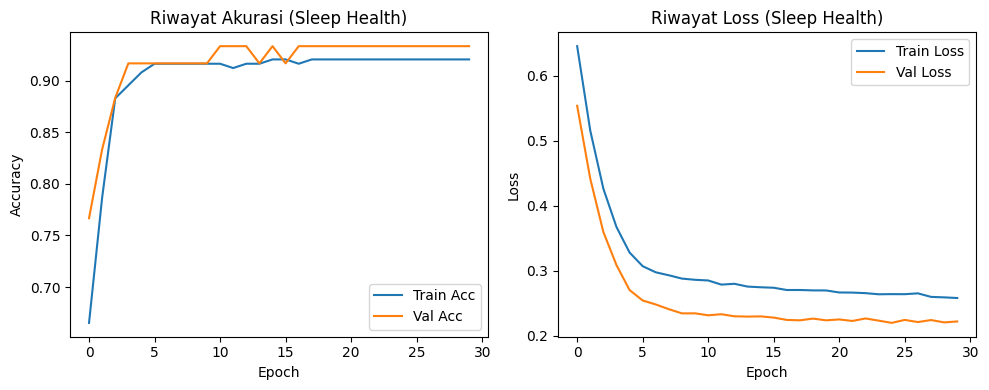

In [15]:
# Visualize training history
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.title('Riwayat Akurasi (Sleep Health)')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Riwayat Loss (Sleep Health)')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

## **Langkah 11 - Menyimpan Model dan Scaler**
Menyimpan model yang sudah dilatih ke dalam format `.h5` dan scaler ke format `.pkl` untuk penggunaan deployment.

In [13]:
# Simpan model Keras
model.save('sleep_health_model.h5')

# Simpan objek StandardScaler
joblib.dump(scaler, 'sleep_health_scaler.pkl')

print("Artefak model dan scaler berhasil disimpan.")

Artefak model dan scaler berhasil disimpan.
